<div style="display:flex; align-items:center; gap:18px; text-align:left">

<div>
<p>Ingeniería en Información y Control de Gestión</p>
<p>Facultad de Economía y Negocios</p>
<p>Introducción a Machine Learning</p>
<p>Semana 07: Clasificación — probabilidades, umbrales y costos</p>
</div>
</div>

# 07 · Clasificación: probabilidades, umbrales y costos

> **La pregunta de hoy:** ¿a qué clientes debe llamar cobranza antes de que dejen de pagar, y cómo
> defendemos esa lista?

Tres tiempos: **yo lo hago** (baseline y regresión logística), **lo hacemos juntos** (matriz, umbral
y costo) y **lo hacen ustedes** (elegir un umbral y defenderlo).

## Preparación del entorno

En Colab estas librerías ya vienen instaladas; la celda queda para correr fuera de Colab. La siguiente
define `num`, que escribe las cifras con punto de miles y coma decimal.

In [1]:
%%capture
!pip install -q pandas numpy scikit-learn matplotlib

In [2]:
from IPython.display import Markdown, display  # muestra frases con las cifras ya calculadas

def num(x, dec=0):
    # miles con punto, decimales con coma y el menos tipográfico
    texto = f'{x:,.{dec}f}'.replace(',', '@').replace('.', ',').replace('@', '.')
    return texto.replace('-', '−')

## Cargar datos

Una cartera de **tarjetas de crédito**, `riesgo_impago.csv`, leída con **pandas**.

<!-- contrato: accion=fijar-base -->

In [3]:
import os                # revisa si el archivo está en una carpeta local
import pandas as pd      # la librería de tablas: lee el archivo y lo deja como DataFrame

REPO = 'https://raw.githubusercontent.com/sebastiancontz/ust-introduccion-machine-learning-colab/main/ediciones/2026/datasets/'
BASE = '../datasets/' if os.path.exists('../datasets') else REPO

datos = pd.read_csv(BASE + 'riesgo_impago.csv')
print('registros y columnas:', datos.shape)
datos.head()

registros y columnas: (6000, 16)


,id_cliente,edad,nivel_educacion,limite_credito,meses_mora,meses_mora_previo,meses_mora_acumulados,monto_facturado_mes,monto_facturado_mes_anterior,monto_facturado_dos_meses_antes,monto_pagado_mes,monto_pagado_mes_anterior,monto_pagado_dos_meses_antes,uso_credito,cobertura_pago,incumplio_pago
0,R-0001,34,universitaria,90000,0,0,0,29239,14027,13559,1518,1500,1000,0.3249,0.0519,no
1,R-0002,37,posgrado,50000,0,0,0,64400,57069,57608,2500,1815,657,1.2880,0.0388,no
2,R-0003,29,posgrado,250000,0,0,0,70887,67060,63561,3000,3000,3000,0.2835,0.0423,no
3,R-0004,26,universitaria,70000,2,0,6,41087,42445,45020,2007,3582,0,0.5870,0.0488,si
4,R-0005,47,media,50000,0,0,0,650,3415,3416,3415,3421,2044,0.0130,3.0000,no


## El encuadre, antes de medir nada

- **Unidad de observación:** un registro es un **cliente observado en un mes**.
- **Objetivo:** si el cliente **incumple el pago del mes siguiente** (`incumplio_pago`, `si` o `no`).
  Es una categoría, no una cantidad: esto es **clasificación**, binaria porque hay dos categorías;
  con más sería multiclase, con la misma lógica.
- **Momento de la predicción:** el cierre del mes observado; solo vale lo anterior a él.
- **Clase positiva:** **incumplir**, el evento que interesa detectar. Todas las métricas de hoy se
  calculan respecto de ella.

La celda codifica el objetivo (1 = incumple, 0 = paga) y deja como predictoras todas las columnas
menos `id_cliente` y el objetivo.

<!-- contrato: accion=declarar-positiva -->

In [4]:
y = datos['incumplio_pago'].map({'no': 0, 'si': 1})  # 1 = incumple, la clase positiva

# nivel_educacion es la única categórica: se prepara distinto que las numéricas
COLUMNAS_CAT = ['nivel_educacion']
COLUMNAS_NUM = []
for columna in datos.columns:  # todas menos el identificador, el objetivo y la categórica
    if columna not in ['id_cliente', 'incumplio_pago'] + COLUMNAS_CAT:
        COLUMNAS_NUM.append(columna)
X = datos[COLUMNAS_NUM + COLUMNAS_CAT]

display(Markdown(
    f'Quedan **{len(COLUMNAS_NUM)}** predictoras numéricas y **{len(COLUMNAS_CAT)}** categórica.'
))

Quedan **13** predictoras numéricas y **1** categórica.

### ¿Hay desbalance de clases? Se mide con `value_counts`

Antes de medir cualquier modelo, hay que contar cuántos registros tiene cada clase. `value_counts`
cuenta los registros por valor, y con `normalize=True` entrega la misma cuenta como proporción.

In [5]:
conteo = datos['incumplio_pago'].value_counts()                     # registros por clase
proporcion = datos['incumplio_pago'].value_counts(normalize=True)   # la misma cuenta, como proporción
pd.DataFrame({'registros': conteo, 'proporción': proporcion.round(3)})

,registros,proporción
incumplio_pago,,
no,4634,0.772
si,1366,0.228


In [6]:
display(Markdown(
    f'Incumple el **{num(100 * proporcion["si"], 1)} %** de los {num(conteo.sum())} registros: '
    f'**{num(conteo["si"])}** contra **{num(conteo["no"])}** que pagan. Hay **desbalance de clases**, '
    f'y la clase positiva, la que interesa detectar, es la **minoritaria**.'
))

Incumple el **22,8 %** de los 6.000 registros: **1.366** contra **4.634** que pagan. Hay **desbalance de clases**, y la clase positiva, la que interesa detectar, es la **minoritaria**.

### La partición: 60 / 20 / 20, estratificada

Es la de la sesión 6: entrenamiento ajusta, validación decide —hoy, el **umbral**— y prueba se abre
una sola vez, en la actividad. `stratify=y` hace que cada pedazo conserve la proporción de
incumplidores. La figura muestra por qué, con 25 clientes de juguete: al azar, validación puede
quedar sin un solo incumplidor, y no habría a quién detectar.

<p align="center"></p>

<!-- contrato: accion=partir-en-tres -->

In [7]:
from sklearn.model_selection import train_test_split  # sortea la partición

# 20 % a prueba, y del resto un 25 % a validación: quedan 60 / 20 / 20
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval)

display(Markdown(
    f'Entrenamiento: **{num(len(X_train))}** · validación: **{num(len(X_val))}** · prueba: '
    f'**{num(len(datos) - len(X_trainval))}**, guardada hasta la actividad. En validación incumplen '
    f'**{num(y_val.sum())}** clientes, el {num(100 * y_val.mean(), 1)} %; en el archivo completo, '
    f'el {num(100 * y.mean(), 1)} %.'
))

Entrenamiento: **3.600** · validación: **1.200** · prueba: **1.200**, guardada hasta la actividad. En validación incumplen **273** clientes, el 22,8 %; en el archivo completo, el 22,8 %.

# Tiempo 1 · Yo lo hago

## El baseline: suponer que todos pagan

`DummyClassifier` con `strategy='most_frequent'` ignora las predictoras y responde siempre la clase
más frecuente, «paga»: la regla de la sesión 1. Lo medimos sobre validación con la *accuracy*
(exactitud), la proporción de clientes bien clasificados que calcula `accuracy_score`, y con cuántos
incumplidores detecta.

<!-- contrato: accion=el-baseline -->

In [8]:
from sklearn.dummy import DummyClassifier   # el modelo que responde siempre lo mismo
from sklearn.metrics import accuracy_score  # la proporción de clientes bien clasificados

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_val)
accuracy_baseline = accuracy_score(y_val, pred_baseline)
detectados_baseline = ((pred_baseline == 1) & (y_val == 1)).sum()

display(Markdown(
    f'El baseline acierta el **{num(100 * accuracy_baseline, 1)} %** de los {num(len(y_val))} '
    f'clientes de validación, justo la proporción de los que pagan, y detecta '
    f'**{num(detectados_baseline)}** de los **{num(y_val.sum())}** que incumplen. Esa accuracy alta '
    f'mide el **desbalance de clases** —una mucho más frecuente que la otra—, no un modelo.'
))

El baseline acierta el **77,2 %** de los 1.200 clientes de validación, justo la proporción de los que pagan, y detecta **0** de los **273** que incumplen. Esa accuracy alta mide el **desbalance de clases** —una mucho más frecuente que la otra—, no un modelo.

## La última pieza del flujo: `LogisticRegression`

Una regresión lineal sobre 0 y 1 puede predecir más de 1, y una probabilidad tiene techo. La
**regresión logística** calcula en dos pasos: **suma** como la lineal,
z = β<sub>0</sub> + β<sub>1</sub>·x<sub>1</sub> + … + β<sub>p</sub>·x<sub>p</sub>, y una **curva en
S** convierte esa suma en probabilidad, p = 1 / (1 + e<sup>−z</sup>), que siempre queda entre 0 y 1.
Aprende por **máxima verosimilitud** (*maximum likelihood*): busca los coeficientes que dan
probabilidad alta a quienes incumplieron y baja a quienes pagaron.

En el `Pipeline` de las sesiones 5 y 6 solo cambia el paso `modelo`. `LogisticRegression`
**regulariza por defecto**, como Ridge, y por eso las numéricas se escalan; `max_iter=2000` le da
vueltas suficientes para converger.

<!-- contrato: accion=el-modelo -->

In [9]:
from sklearn.pipeline import Pipeline             # encadena la preparación y el modelo
from sklearn.compose import ColumnTransformer     # prepara cada grupo de columnas a su manera
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression  # la regresión logística

modelo = Pipeline([
    ('preparar', ColumnTransformer([
        ('num', StandardScaler(), COLUMNAS_NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), COLUMNAS_CAT),
    ])),
    ('modelo', LogisticRegression(max_iter=2000)),  # la única pieza que cambia
])
modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['edad','limite_credito','meses_mora',...,'uso_credito','cobertura_pago', 'nivel_educacion']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

## `predict` da una etiqueta; `predict_proba`, un número

`predict` devuelve 0 (paga) o 1 (incumple) con un umbral interno de 0,5. `predict_proba` devuelve una
columna de probabilidad por clase, en el orden de `modelo.classes_`; la de incumplir es la segunda,
`[:, 1]`. Para gestión se quiere la probabilidad: deja la decisión a quien conoce el costo de cada
error.

<!-- contrato: accion=la-probabilidad -->

In [10]:
print('orden de las columnas de predict_proba:', modelo.classes_)
prob_val = modelo.predict_proba(X_val)[:, 1]   # la probabilidad de incumplir, cliente por cliente

clientes_val = pd.DataFrame({'id_cliente': datos.loc[X_val.index, 'id_cliente'],
                             'probabilidad': prob_val,
                             'predict': modelo.predict(X_val)})
display(clientes_val.head().round(3))

iguales = ((prob_val >= 0.5) == clientes_val['predict']).sum()
display(Markdown(
    f'En **{num(iguales)}** de los **{num(len(clientes_val))}** clientes de validación, `predict` '
    f'coincide con preguntar si la probabilidad llega a 0,5: **`predict` usa un 0,5 que nadie eligió**.'
))

orden de las columnas de predict_proba: [0 1]


,id_cliente,probabilidad,predict
4607,R-4608,0.133,0
5804,R-5805,0.578,1
633,R-0634,0.297,0
5990,R-5991,0.116,0
744,R-0745,0.148,0


En **1.200** de los **1.200** clientes de validación, `predict` coincide con preguntar si la probabilidad llega a 0,5: **`predict` usa un 0,5 que nadie eligió**.

### Cuatro clientes, su suma z y su probabilidad

`decision_function` devuelve la suma z de cada cliente, antes de la curva en S; `predict_proba` es esa
suma pasada por la curva. Cuatro clientes de validación, con tres de las catorce predictoras:

In [11]:
cuatro = ['R-2911', 'R-1637', 'R-3258', 'R-0823']        # los clientes marcados en la figura
en_validacion = datos.loc[X_val.index]
marcados = en_validacion['id_cliente'].isin(cuatro).to_numpy()
tabla_z = en_validacion.loc[marcados, ['id_cliente', 'meses_mora', 'uso_credito', 'cobertura_pago',
                                       'incumplio_pago']]
tabla_z['z'] = modelo.decision_function(X_val[marcados])  # la suma, antes de la curva en S
tabla_z['probabilidad'] = prob_val[marcados]              # la suma, después de la curva
tabla_z.sort_values('z').round(4)   # cuatro decimales: R-3258 queda justo bajo 0,5

,id_cliente,meses_mora,uso_credito,cobertura_pago,incumplio_pago,z,probabilidad
2910,R-2911,0,1.0030,0.0067,no,-2.9861,0.0481
1636,R-1637,0,0.0275,3.0000,si,-1.8011,0.1417
3257,R-3258,2,0.9360,0.0860,si,-0.0015,0.4996
822,R-0823,4,0.6971,0.0000,si,2.4570,0.9211


<p align="center"><img src="" width="860" alt="Regresión logística ajustada a la cartera: en el eje horizontal, z, la suma del modelo con las 14 predictoras; en el vertical, la probabilidad de incumplir. La curva en S pasa por 0,5 cuando z vale 0. Cada cliente de validación es un punto en su z: arriba, en 1, los que incumplieron; abajo, en 0, los que pagaron. Los cuatro clientes de la tabla están marcados con su identificador y con su probabilidad sobre la curva. A la derecha predominan los de arriba y a la izquierda los de abajo, pero en el medio se mezclan."></p>

Cada punto es un cliente de validación en su z: arriba, los que incumplieron; abajo, los que pagaron.
A más suma, más probabilidad, pero `R-1637` incumplió con una suma baja: en el medio las clases se
mezclan. Por eso la probabilidad sirve para **ordenar** a quién llamar primero si el equipo alcanza
para pocos. Ordenar no es acertar la frecuencia: un 0,9 del modelo no asegura 9 de cada 10.

Los primeros de la lista:

In [12]:
clientes_val.sort_values('probabilidad', ascending=False).head().round(3)

,id_cliente,probabilidad,predict
1728,R-1729,0.999,1
3861,R-3862,0.999,1
1290,R-1291,0.987,1
1705,R-1706,0.970,1
3371,R-3372,0.969,1


## Un coeficiente se lee como odds ratio

Los **odds** dividen la probabilidad de que algo ocurra por la de que no ocurra, p / (1 − p): 0,75
son odds de 3, «tres a uno». Un coeficiente se comunica como **odds ratio**, e<sup>β</sup>: cuánto se
multiplican los odds al subir la variable en una unidad, manteniendo las demás iguales; **1** es sin
efecto.

Para leerlo en unidades del negocio ajustamos una **segunda logística**, sin escalar, con dos
predictoras: `meses_mora`, meses de atraso, y `uso_credito`, lo facturado como fracción del cupo.
`coef_` guarda sus coeficientes y `np.exp`, de **NumPy**, calcula la exponencial.

<!-- contrato: accion=odds-ratio -->

In [13]:
import numpy as np  # cálculo numérico: acá, la exponencial

legibles = ['meses_mora', 'uso_credito']
dos_predictoras = LogisticRegression(max_iter=2000).fit(X_train[legibles], y_train)
odds_ratio = pd.DataFrame({'odds ratio': np.exp(dos_predictoras.coef_[0])}, index=legibles)
display(odds_ratio.round(2))

mora = odds_ratio.loc['meses_mora', 'odds ratio']
uso = odds_ratio.loc['uso_credito', 'odds ratio']
display(Markdown(
    f'Cada mes más de mora, **manteniendo igual el uso del cupo**, multiplica los odds de incumplir '
    f'por **{num(mora, 2)}**. Usar el cupo entero en vez de nada, **manteniendo igual la mora**, los '
    f'multiplica por **{num(uso, 2)}**. Se multiplican los odds, no la probabilidad, y es una '
    f'**asociación**, no un efecto.'
))

,odds ratio
meses_mora,3.20
uso_credito,1.35


Cada mes más de mora, **manteniendo igual el uso del cupo**, multiplica los odds de incumplir por **3,20**. Usar el cupo entero en vez de nada, **manteniendo igual la mora**, los multiplica por **1,35**. Se multiplican los odds, no la probabilidad, y es una **asociación**, no un efecto.

### Una probabilidad, calculada paso a paso

La misma cuenta, a mano, para el cliente de validación `R-0253`, con los coeficientes de esa
logística redondeados a dos decimales para poder repetirla con calculadora:

In [14]:
cliente = en_validacion.loc[en_validacion['id_cliente'] == 'R-0253', legibles]  # un cliente de validación
b0 = round(dos_predictoras.intercept_[0], 2)          # el término constante, a dos decimales
b_mora, b_uso = dos_predictoras.coef_[0].round(2)     # un coeficiente por predictora, a dos decimales
mora_c, uso_c = cliente.iloc[0].round(2)

z = b0 + b_mora * mora_c + b_uso * uso_c  # paso 1: la suma
p_mano = 1 / (1 + np.exp(-z))             # paso 2: la curva en S
p_modelo = dos_predictoras.predict_proba(cliente)[0, 1]
display(Markdown(
    f'Cliente `R-0253`: z = {num(b0, 2)} + {num(b_mora, 2)} × {num(mora_c)} + {num(b_uso, 2)} × '
    f'{num(uso_c, 2)} = **{num(z, 2)}**, y p = 1 / (1 + e<sup>−{num(z, 2)}</sup>) = **{num(p_mano, 2)}**. '
    f'`predict_proba` da {num(p_modelo, 2)}: es la misma cuenta. Con las catorce predictoras es igual, '
    f'con más sumandos.'
))

Cliente `R-0253`: z = −1,89 + 1,16 × 2 + 0,30 × 0,74 = **0,65**, y p = 1 / (1 + e<sup>−0,65</sup>) = **0,66**. `predict_proba` da 0,66: es la misma cuenta. Con las catorce predictoras es igual, con más sumandos.

# Tiempo 2 · Lo hacemos juntos

## La matriz de confusión, con el umbral en 0,5

La lista de llamadas sale de un **umbral**: entra quien lo alcanza, y con otro umbral la matriz
cambia. `confusion_matrix` recibe lo observado y lo predicho: las filas son lo que pasó y las columnas
lo predicho, `labels=[0, 1]` fija el orden de las clases, y `.ravel()` entrega verdaderos negativos (VN), falsos positivos
(FP), falsos negativos (FN) y verdaderos positivos (VP). Un FP es una **falsa alarma**, una llamada de
más; un FN, un **impago que se escapa**. No cuestan lo mismo. `ConfusionMatrixDisplay` la dibuja con
los mismos argumentos, y la diagonal da la accuracy, que comparamos con la del baseline.

<!-- contrato: accion=la-matriz -->

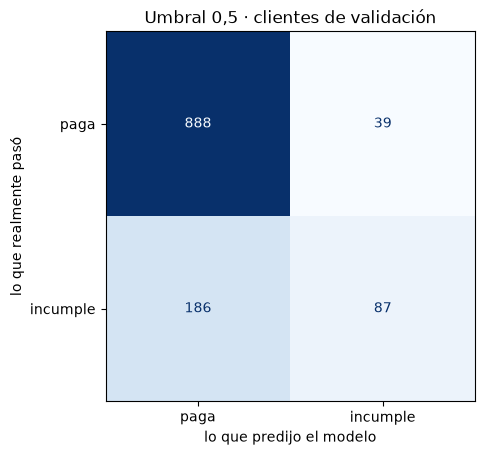

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay  # cuenta y dibuja los cuatro resultados
import matplotlib.pyplot as plt

UMBRAL_DEFECTO = 0.5
lista_05 = np.where(prob_val >= UMBRAL_DEFECTO, 1, 0)   # 1 = entra en la lista de llamadas
vn, fp, fn, vp = confusion_matrix(y_val, lista_05, labels=[0, 1]).ravel()
matriz = ConfusionMatrixDisplay.from_predictions(y_val, lista_05, display_labels=['paga', 'incumple'],
                                                 cmap='Blues', colorbar=False)
matriz.ax_.set(xlabel='lo que predijo el modelo', ylabel='lo que realmente pasó',
               title='Umbral 0,5 · clientes de validación')
plt.show()

In [16]:
accuracy_modelo = accuracy_score(y_val, lista_05)   # la diagonal sobre el total
display(Markdown(
    f'Accuracy: ({num(vn)} + {num(vp)}) / {num(len(y_val))} = **{num(100 * accuracy_modelo, 1)} %**, '
    f'contra **{num(100 * accuracy_baseline, 1)} %** del baseline. Casi no los separa, y sin embargo el '
    f'modelo detecta **{num(vp)}** incumplidores donde el baseline detectaba **{num(detectados_baseline)}**.'
))

Accuracy: (888 + 87) / 1.200 = **81,2 %**, contra **77,2 %** del baseline. Casi no los separa, y sin embargo el modelo detecta **87** incumplidores donde el baseline detectaba **0**.

## Precision y recall: una columna y una fila

- **Precision**, sobre la columna «predijo incumple»: de las alarmas, qué parte era un impago de
  verdad. No se traduce como «precisión», que suena a accuracy.
- **Recall**, sobre la fila «realmente incumple»: de los que incumplieron, qué parte se detectó.

`precision_score` y `recall_score` reciben lo observado y lo predicho, y las calculan respecto de la
clase 1.

<!-- contrato: accion=precision-recall -->

In [17]:
from sklearn.metrics import precision_score, recall_score  # las dos lecturas de la matriz

precision_05 = precision_score(y_val, lista_05)
recall_05 = recall_score(y_val, lista_05)
display(Markdown(
    f'- **precision** = VP / (VP + FP) = {num(vp)} / ({num(vp)} + {num(fp)}) = '
    f'**{num(100 * precision_05)} %**: de cada 100 alarmas, unas {num(100 * precision_05)} aciertan.\n'
    f'- **recall** = VP / (VP + FN) = {num(vp)} / ({num(vp)} + {num(fn)}) = '
    f'**{num(100 * recall_05)} %**: de cada 100 que incumplen, se detectan unos {num(100 * recall_05)}.'
))

- **precision** = VP / (VP + FP) = 87 / (87 + 39) = **69 %**: de cada 100 alarmas, unas 69 aciertan.
- **recall** = VP / (VP + FN) = 87 / (87 + 186) = **32 %**: de cada 100 que incumplen, se detectan unos 32.

### F1: precision y recall en una sola cifra

**F1** es su **media armónica**: solo es alto si las dos lo son. En conteos,
F1 = 2 × VP / (2 × VP + FP + FN), así que una falsa alarma y un impago que se escapa **pesan lo
mismo**. Sirve para comparar cuando los dos errores importan igual, no para elegir el umbral cuando
cuestan distinto. Lo calcula `f1_score`.

<!-- contrato: accion=f1 -->

In [18]:
from sklearn.metrics import f1_score  # media armónica de precision y recall

f1_05 = f1_score(y_val, lista_05)
promedio_simple = (precision_05 + recall_05) / 2
display(Markdown(
    f'Con el umbral en 0,5: F1 = 2 × {num(vp)} / (2 × {num(vp)} + {num(fp)} + {num(fn)}) = '
    f'**{num(f1_05, 2)}**. El promedio simple de precision y recall daría {num(promedio_simple, 2)}: '
    f'F1 queda más cerca de la que falla, que es el recall.'
))

Con el umbral en 0,5: F1 = 2 × 87 / (2 × 87 + 39 + 186) = **0,44**. El promedio simple de precision y recall daría 0,50: F1 queda más cerca de la que falla, que es el recall.

## Mover el umbral: el barrido sobre validación

0,5 supone dos cosas a la vez: que los dos errores cuestan lo mismo y que la probabilidad es fiel.
Como no comprobamos ninguna, el umbral se **mide** sobre validación: una grilla de 0,05 a 0,90 y, para
cada umbral, sus dos errores, precision y recall. **El modelo no se reentrena**: solo cambia dónde se
corta.

<!-- contrato: accion=barrer-umbral -->

In [19]:
GRILLA = np.round(np.arange(0.05, 0.91, 0.05), 2)   # de 0,05 a 0,90, de a 0,05

filas = []
for umbral in GRILLA:
    lista = np.where(prob_val >= umbral, 1, 0)   # las mismas probabilidades, otro umbral
    _, falsas, escapados, _ = confusion_matrix(y_val, lista, labels=[0, 1]).ravel()
    filas.append({'umbral': umbral, 'falsas_alarmas': falsas, 'impagos_escapados': escapados,
                  'precision': precision_score(y_val, lista), 'recall': recall_score(y_val, lista)})
barrido = pd.DataFrame(filas)
barrido.round(2)

,umbral,falsas_alarmas,impagos_escapados,precision,recall
0,0.05,905,0,0.23,1.00
1,0.10,827,11,0.24,0.96
2,0.15,452,57,0.32,0.79
3,0.20,159,124,0.48,0.55
4,0.25,126,137,0.52,0.50
5,0.30,83,151,0.60,0.45
6,0.35,75,157,0.61,0.42
7,0.40,65,162,0.63,0.41
8,0.45,53,174,0.65,0.36
9,0.50,39,186,0.69,0.32


In [20]:
bajo, alto = barrido.iloc[0], barrido.iloc[-1]   # los dos extremos de la grilla
display(Markdown(
    f'Los extremos primero. Con **{num(bajo["umbral"], 2)}** se escapan **{num(bajo["impagos_escapados"])}** '
    f'impagos a cambio de **{num(bajo["falsas_alarmas"])}** falsas alarmas; con **{num(alto["umbral"], 2)}** '
    f'quedan **{num(alto["falsas_alarmas"])}** falsas alarmas, pero se escapan '
    f'**{num(alto["impagos_escapados"])}** de los {num(y_val.sum())} impagos. La decisión está entre los dos.'
))

Los extremos primero. Con **0,05** se escapan **0** impagos a cambio de **905** falsas alarmas; con **0,90** quedan **4** falsas alarmas, pero se escapan **264** de los 273 impagos. La decisión está entre los dos.

## El costo de cada error decide el umbral

Cuánto cuesta cada error lo decide la organización. Si acuerda que dejar pasar un impago cuesta
**cinco** llamadas de más:

> **costo total = 5 × impagos que se escapan + 1 × falsas alarmas**

Se trabaja con una **razón** y no con montos, porque una razón se acuerda en una reunión. Primero tres
umbrales; después, el más barato de la grilla.

<!-- contrato: accion=costo-cinco -->

In [21]:
# un impago que se escapa vale 5 llamadas de más; una falsa alarma, 1
barrido['costo_5_a_1'] = 5 * barrido['impagos_escapados'] + barrido['falsas_alarmas']
display(barrido.loc[barrido['umbral'].isin([0.10, 0.15, 0.50]),
                    ['umbral', 'falsas_alarmas', 'impagos_escapados', 'costo_5_a_1']])

mas_barato = barrido.loc[barrido['costo_5_a_1'].idxmin()]
costo_1_a_1 = barrido['impagos_escapados'] + barrido['falsas_alarmas']   # los dos errores pesan igual
umbral_1_a_1 = barrido.loc[costo_1_a_1.idxmin(), 'umbral']
display(Markdown(
    f'En toda la grilla, el umbral más barato con razón 5 a 1 es **{num(mas_barato["umbral"], 2)}**, con '
    f'un costo de **{num(mas_barato["costo_5_a_1"])}**. Si los dos errores costaran lo mismo, sería '
    f'**{num(umbral_1_a_1, 2)}** en esta validación. No es una regla general: la grilla avanza de a 0,05 '
    f'y no comprobamos que la probabilidad sea fiel.'
))

,umbral,falsas_alarmas,impagos_escapados,costo_5_a_1
1,0.10,827,11,882
2,0.15,452,57,737
9,0.50,39,186,969


En toda la grilla, el umbral más barato con razón 5 a 1 es **0,15**, con un costo de **737**. Si los dos errores costaran lo mismo, sería **0,50** en esta validación. No es una regla general: la grilla avanza de a 0,05 y no comprobamos que la probabilidad sea fiel.

## Una cifra para todos los umbrales: ROC-AUC

La curva **ROC** marca, para cada umbral, la tasa de verdaderos positivos (el recall) contra la tasa
de falsos positivos (la parte de los que pagan que recibe una falsa alarma). **AUC** es el área bajo
ella: 0,5 es ordenar al azar y 1, ordenar perfecto. `RocCurveDisplay` la dibuja a partir de lo
observado y la probabilidad; los dos puntos son los umbrales 0,50 y 0,15 del barrido.

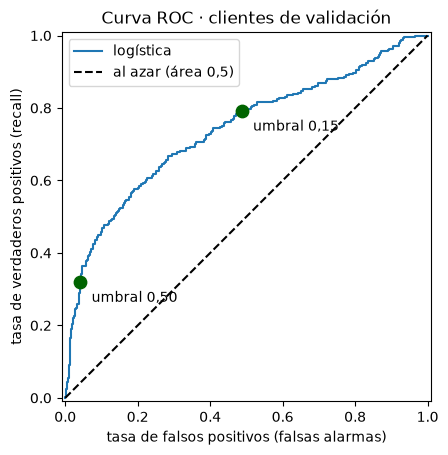

In [22]:
from sklearn.metrics import RocCurveDisplay  # dibuja la curva ROC

curva = RocCurveDisplay.from_predictions(y_val, prob_val, name='logística', plot_chance_level=True)
for u in (0.50, 0.15):  # los dos umbrales de la clase, como puntos de la curva
    fila = barrido.loc[np.isclose(barrido['umbral'], u)].iloc[0]
    x, y_punto = fila['falsas_alarmas'] / (y_val == 0).sum(), fila['recall']
    curva.ax_.scatter(x, y_punto, s=80, color='darkgreen', zorder=3)
    curva.ax_.annotate(f'umbral {num(u, 2)}', (x, y_punto), xytext=(8, -14), textcoords='offset points')
curva.ax_.legend([curva.line_, curva.chance_level_], ['logística', 'al azar (área 0,5)'])
curva.ax_.set(xlabel='tasa de falsos positivos (falsas alarmas)',
              ylabel='tasa de verdaderos positivos (recall)', title='Curva ROC · clientes de validación')
plt.show()

`roc_auc_score` recibe lo observado y la **probabilidad**, no la etiqueta, porque resume qué tan bien
**ordena** el modelo. La celda también lo lee como pares: cada cliente que incumple contra cada uno
que paga.

<!-- contrato: accion=roc-auc -->

In [23]:
from sklearn.metrics import roc_auc_score  # resume el orden en todos los umbrales a la vez

auc_val = roc_auc_score(y_val, prob_val)
incumplen = prob_val[y_val.to_numpy() == 1]  # probabilidad de cada cliente que incumplió
pagan = prob_val[y_val.to_numpy() == 0]      # y de cada cliente que pagó
bien_ordenados = (incumplen[:, None] > pagan).mean()  # cada uno que incumple contra cada uno que paga
display(Markdown(
    f'Sobre validación, el ROC-AUC vale **{num(auc_val, 2)}**: de los '
    f'**{num(len(incumplen) * len(pagan))}** pares posibles, en **{num(100 * bien_ordenados)} de cada '
    f'100** el cliente que incumple recibe más probabilidad que el que paga. Mide el **orden**, no la '
    f'**lista**: el umbral se elige con la matriz y el costo.'
))

Sobre validación, el ROC-AUC vale **0,74**: de los **253.071** pares posibles, en **74 de cada 100** el cliente que incumple recibe más probabilidad que el que paga. Mide el **orden**, no la **lista**: el umbral se elige con la matriz y el costo.

# Tiempo 3 · Lo hacen ustedes

## La actividad: elegir un umbral y defenderlo

Cobranza y comercial no se ponen de acuerdo en cuánto cuesta cada error:

- **Cobranza:** detrás de un impago vienen el saldo expuesto y su recuperación. **Un impago que se
  escapa vale 4 llamadas de más.**
- **Comercial:** llamar a quien iba a pagar molesta al cliente y consume horas del equipo. **Un impago
  que se escapa vale 1,5 llamadas de más.**

1. **Elijan una posición** y escriban su razón en la celda `razon`.
2. **Corran el costo de cada umbral** sobre validación y anoten el más barato.
3. **Abran prueba una sola vez** con ese umbral y anoten cuánto ahorra frente a 0,5.
4. **Defiendan su lista en tres líneas:** a quién llaman, cuántos impagos se les escapan y quién paga
   ese costo.

**Criterio de éxito:** las tres líneas nombran los dos errores y qué le pasa a cada uno con el umbral
elegido.

**Evidencia observable:** la tabla del barrido, el umbral con su posición y las tres líneas; el
**feedback formativo** llega en la puesta en común.

### Paso 1 · Elegir una posición

La celda corre con cobranza. Para comercial, cambien el `4` por `1.5` —con punto, porque es código— y
vuelvan a correr desde ahí. Si quieren hacer la actividad sin ver antes el resultado de cobranza, borren
primero los resultados (en Colab, Editar → Borrar todos los resultados) y corran desde el inicio.

<!-- contrato: accion=elegir-posicion -->

In [24]:
# si eligen comercial, cambien el 4 por 1.5 y vuelvan a correr desde esta celda
razon = 4  # cobranza: 4 · comercial: 1.5

### Paso 2 · El costo de cada umbral, sobre validación

La cuenta de la razón 5 a 1, con el peso de su posición. Prueba sigue cerrada.

<!-- contrato: accion=elegir-umbral -->

In [25]:
barrido['costo'] = razon * barrido['impagos_escapados'] + barrido['falsas_alarmas']
umbral_elegido = barrido.loc[barrido['costo'].idxmin(), 'umbral']

dec = 0 if float(razon).is_integer() else 1   # 4 se escribe «4»; 1.5, «1,5»
display(Markdown(f'Con razón **{num(razon, dec)} a 1**, el umbral más barato sobre validación es '
                 f'**{num(umbral_elegido, 2)}**.'))
display(barrido[['umbral', 'falsas_alarmas', 'impagos_escapados', 'precision', 'recall', 'costo']].round(2))

Con razón **4 a 1**, el umbral más barato sobre validación es **0,20**.

,umbral,falsas_alarmas,impagos_escapados,precision,recall,costo
0,0.05,905,0,0.23,1.00,905
1,0.10,827,11,0.24,0.96,871
2,0.15,452,57,0.32,0.79,680
3,0.20,159,124,0.48,0.55,655
4,0.25,126,137,0.52,0.50,674
5,0.30,83,151,0.60,0.45,687
6,0.35,75,157,0.61,0.42,703
7,0.40,65,162,0.63,0.41,713
8,0.45,53,174,0.65,0.36,749
9,0.50,39,186,0.69,0.32,783


### Paso 3 · Abrir prueba, una sola vez

La razón la puso su posición y el umbral lo eligió validación: ya no queda nada por decidir. Es la
**única celda que lee prueba**, y el modelo no se reajusta antes, porque el umbral se eligió para sus
probabilidades.

<!-- contrato: accion=abrir-la-prueba -->

In [26]:
prob_test = modelo.predict_proba(X_test)[:, 1]   # prueba se abre acá, y solo acá
_, fp_elegido, fn_elegido, _ = confusion_matrix(
    y_test, np.where(prob_test >= umbral_elegido, 1, 0), labels=[0, 1]).ravel()
_, fp_defecto, fn_defecto, _ = confusion_matrix(
    y_test, np.where(prob_test >= UMBRAL_DEFECTO, 1, 0), labels=[0, 1]).ravel()

costo_elegido = razon * fn_elegido + fp_elegido
costo_defecto = razon * fn_defecto + fp_defecto
ahorro = (costo_defecto - costo_elegido) / costo_defecto

In [27]:
display(Markdown(
    f'Sobre los **{num(len(prob_test))}** clientes de prueba, con razón {num(razon, dec)} a 1:\n\n'
    f'- con su umbral, **{num(umbral_elegido, 2)}**: {num(fp_elegido)} llamadas de más y '
    f'{num(fn_elegido)} impagos que se escapan, con un costo de **{num(costo_elegido, dec)}**;\n'
    f'- con **{num(UMBRAL_DEFECTO, 2)}**: {num(fp_defecto)} llamadas de más y {num(fn_defecto)} '
    f'impagos que se escapan, con un costo de **{num(costo_defecto, dec)}**.\n\n'
    f'Su umbral ahorra el **{num(100 * ahorro)} %** del costo frente a 0,5.'
))

Sobre los **1.200** clientes de prueba, con razón 4 a 1:

- con su umbral, **0,20**: 148 llamadas de más y 131 impagos que se escapan, con un costo de **672**;
- con **0,50**: 43 llamadas de más y 194 impagos que se escapan, con un costo de **819**.

Su umbral ahorra el **18 %** del costo frente a 0,5.

### Paso 4 · Su defensa, en tres líneas

El umbral **reparte el error entre personas**: bajarlo detecta más impagos y señala a más clientes
que iban a pagar. Por eso la decisión es de la organización, no del algoritmo. Con las cifras de los
pasos 2 y 3:

1. A quién llaman:
2. Cuántos impagos se les escapan:
3. Quién paga ese costo:

# Cierre

## A quién llamar, y cómo defender la lista

Cobranza llama a los clientes cuya probabilidad alcanza el umbral que **minimiza el costo total** con
la razón que acuerda la organización. La accuracy no defiende esa lista; la matriz y el costo, sí. El
umbral se elige **sobre validación** y el ahorro se informa **con prueba, abierta una sola vez**. Si
cambia la razón, cambia la lista; el modelo es el mismo.

Ese umbral lo eligió **una** partición de validación, y con otra podría ser otro. Cómo elegir sin
depender de una sola partición es la pregunta de la sesión 8.

## Atribución de datos

- **Creador:** Yeh, I. C., & Lien, C. H. (2009)
- **Fuente:** [UCI Machine Learning Repository — *Default of Credit Card Clients*, dataset 350](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)
- **Licencia:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)
- **Modificación:** obra derivada. Se tomaron 6.000 registros y 16 columnas del original de 30.000 ×
  25, con los nombres traducidos al español en `snake_case`, la escolaridad recodificada a etiquetas y
  dos razones derivadas nuevas; [`_prep_riesgo_impago.py`](https://github.com/sebastiancontz/ust-introduccion-machine-learning-colab/blob/main/ediciones/2026/datasets/_prep_riesgo_impago.py) documenta cada paso. Los
  atributos sexo y estado civil se excluyeron deliberadamente.